# 01-ROS发展史与AI机器人技术概览


## 1. 本篇目标与课程路线

这套“AI+机器人开发”资料的课程目录名为 **《ROS 2零代码到全栈》**。本篇对应《ROS发展史.pdf》，先建立机器人软件架构的整体认识，再进入环境搭建和开发。

学完本篇，应能回答：ROS解决什么问题？ROS1的Master负责什么？ROS2为什么引入DDS？大模型、ROS与底层实时控制怎样协作？

| 笔记 | 主题 | 学习结果 |
|---|---|---|
| 01 | ROS发展史与AI机器人技术概览 | 理解ROS定位、架构演进和应用方向 |
| 02 | ROS2开发环境搭建 | 建立可用的开发环境 |
| 03 | ROS2工作空间、功能包与节点开发 | 理解工程组织和节点开发 |
| 04 | ROS2 Topic通信与机器人协作 | 让不同模块通过消息协作 |
| 05 | ROS2视觉识别、坐标转换与机械臂控制 | 将视觉结果连接到机械臂动作 |
| 06 | ROS2语音、大模型与MCP机器人控制 | 将自然语言任务连接到机器人能力 |

**资料依据：**网盘中的《ROS发展史.pdf》共25页，已逐页核对PDF页面预览；本篇覆盖1—24页教学内容，第25页仅为品牌结束页。图注标明原课件页码。未将课程视频或源码压缩包作为已阅读资料。文中“工程补充”用于解释课件简化之处，不属于课件原文。


## 2. ROS的起源：从实验室走向可复用的软件生态

课件以斯坦福研究团队、STAIR项目和PR2机器人说明ROS的起源，并把2007年前后作为这段历史的起点。随后Willow Garage推动ROS与机器人研究平台的发展，开源协作使其逐渐形成庞大的机器人软件生态。

早期机器人开发常见的问题是：不同团队都在重复编写传感器驱动、消息传输、调试工具和工程框架。算法虽然各有特色，底层基础却难以复用。

例如，同样使用摄像头，一个团队自己定义图像数据格式，另一个团队自己写网络接口。即使两边算法都能运行，组合起来也需要大量接口适配。ROS尝试让这些模块拥有共同的通信方式、数据约定和工具体系。

**历史的学习价值：**理解ROS为何强调节点、消息和模块复用，才能理解后续开发为什么围绕功能包和通信接口展开。

课件用“90%与10%”对比基础框架工作与算法工作的投入，表达“复用基础能力，集中精力解决机器人任务”。这是教学示意，不能当成适用于所有项目的统计结果。


## 3. ROS的定位：机器人中间件

ROS是 **Robot Operating System** 的缩写。虽然名称包含“操作系统”，但学习时应把它主要理解为机器人软件的中间件、库与工具集合。

普通操作系统负责进程、内存、文件、设备等基础管理；ROS建立在这些能力之上，帮助机器人模块发现彼此、交换信息、组织工程、调试运行状态。

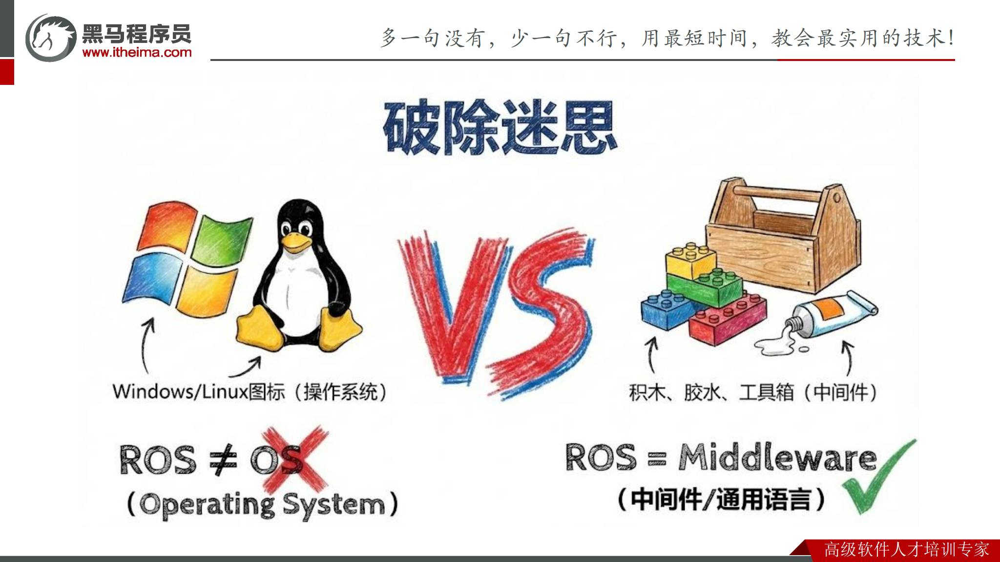

*原课件第5页：ROS作为机器人系统的通用软件连接层。*

可以用四层结构理解：

| 层次 | 典型内容 | 主要职责 |
|---|---|---|
| 机器人应用 | 导航、抓取、语音任务 | 实现机器人行为 |
| ROS及相关算法库 | 节点通信、工具、感知和规划组件 | 组织模块与数据流 |
| 操作系统 | Linux等 | 提供进程、网络、驱动等运行基础 |
| 硬件 | 摄像头、电机、机械臂、计算板 | 感知环境和执行动作 |

**工程补充：**ROS不会自动提供完整的机器人智能，也不会自动完成电机闭环控制。实际能力来自应用算法、硬件驱动、控制器和通信系统的共同配合。


## 4. ROS的三大支柱：通信、生态与工具

课件将ROS的核心价值归纳为三个方面。

| 支柱 | 内容 | 解决的问题 |
|---|---|---|
| 通信机制 | 节点之间交换消息和请求 | 让不同软件模块协作 |
| 生态系统 | 驱动、算法包、公共接口 | 减少重复开发，提高组件复用能力 |
| 工具箱 | RViz、Gazebo等 | 帮助观察、调试和仿真 |

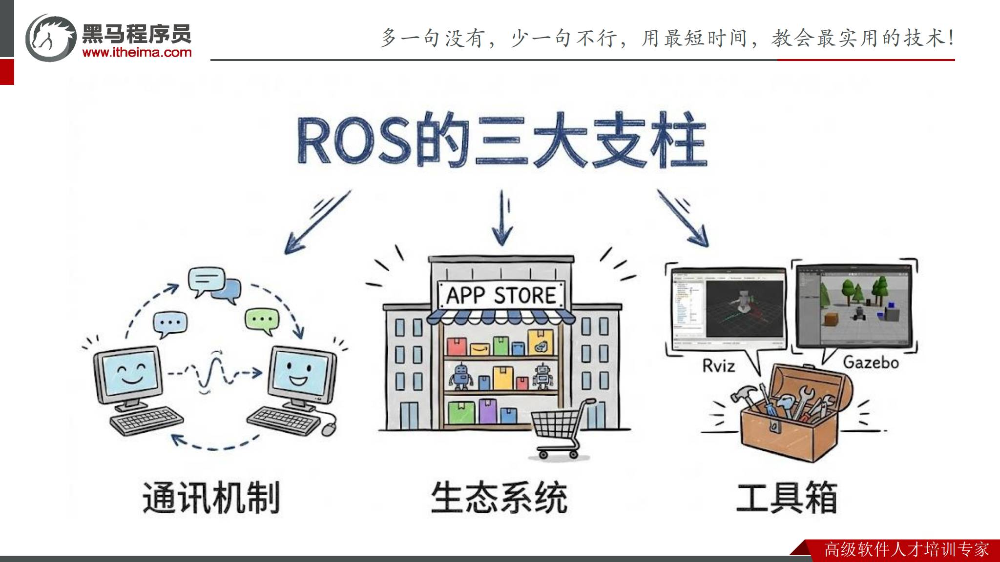

*原课件第6页：通信机制、生态系统与工具箱。*

**RViz主要用于可视化。**例如显示机器人模型、坐标系、点云和规划结果。它让开发者看见节点所表达的数据。

**Gazebo主要用于仿真。**可以在虚拟环境中模拟机器人、传感器和物理运动。仿真结果能帮助开发，但仍需在真实硬件上验证。

**工程补充：**可视化不等于物理仿真。RViz显示一个机械臂模型，并不意味着它已经模拟了关节动力学；不同ROS发行版与Gazebo版本也需要匹配。


## 5. 从“烟囱式开发”到模块化机器人

课件中的“烟囱式开发”指每个模块拥有自己的一套接口和工具，彼此之间难以互通。ROS将视觉、导航、控制、驱动等模块连接在共同的软件体系中。

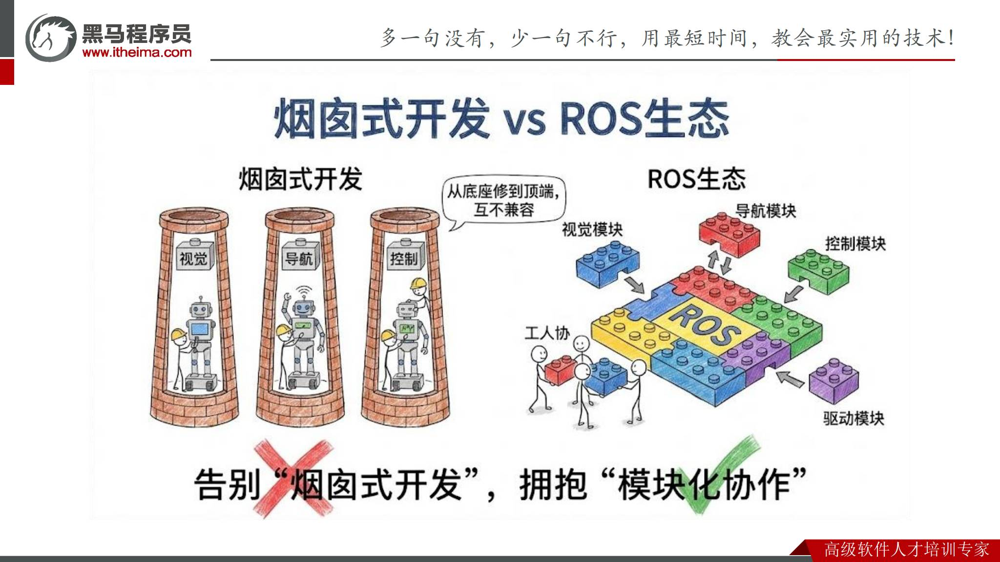

*原课件第8页：独立开发模块与ROS模块化生态的对比。*

以“识别桌上的物体并抓取”为例，可以拆成：

1. 摄像头驱动产生图像。
2. 视觉节点识别目标。
3. 坐标转换模块把视觉位置转换到机器人坐标系。
4. 规划模块计算可执行的运动路径。
5. 控制模块把轨迹交给硬件执行。

模块化的价值在于可以替换其中一个模块，而不必重写整个系统。但前提是接口约定清楚：消息类型、单位、坐标系、时间戳和运行频率都需要一致。

**工程补充：**“都使用ROS”不代表两个模块可以立即连接。例如一个节点给出毫米，另一个按米解释，就可能产生严重的位置错误。软件框架提供连接机制，工程人员仍需保证数据含义正确。


## 6. ROS1的核心概念：Node、Topic、Service与Master

| 概念 | 含义 | 机器人例子 |
|---|---|---|
| Node（节点） | 参与ROS通信的功能单元 | 摄像头节点、识别节点、控制节点 |
| Topic（话题） | 发布与订阅消息的命名通道 | 连续发布图像或关节状态 |
| Service（服务） | 请求与响应式接口 | 请求读取某项配置并返回结果 |
| Master | ROS1的注册与发现协调组件 | 让发布者与订阅者找到彼此 |

**Topic适合数据流。**发布者不断产生消息，订阅者接收并处理；双方不必通过同步调用绑定在一起。

**Service适合请求与响应。**调用者提出一次请求，服务端处理后返回结果。持续图像流通常不适合用一次次同步请求来组织。

**工程补充：**节点是逻辑概念，不应绝对理解为“一节点一定对应一进程”。后续还会遇到节点组合等部署方式。长时间执行且需要反馈或取消的任务通常可考虑Action，这里只作为后续概念预告。

举例说明信息流：摄像头节点发布图像话题，视觉节点订阅图像并发布识别结果，任务节点订阅结果后组织抓取流程。Master帮助它们建立联系，但不承担视觉识别或运动规划。


## 7. ROS1如何通信：先注册发现，再直接传输

课件将ROS1通信分为“向Master注册、协商连接、节点直接通信”几个阶段。

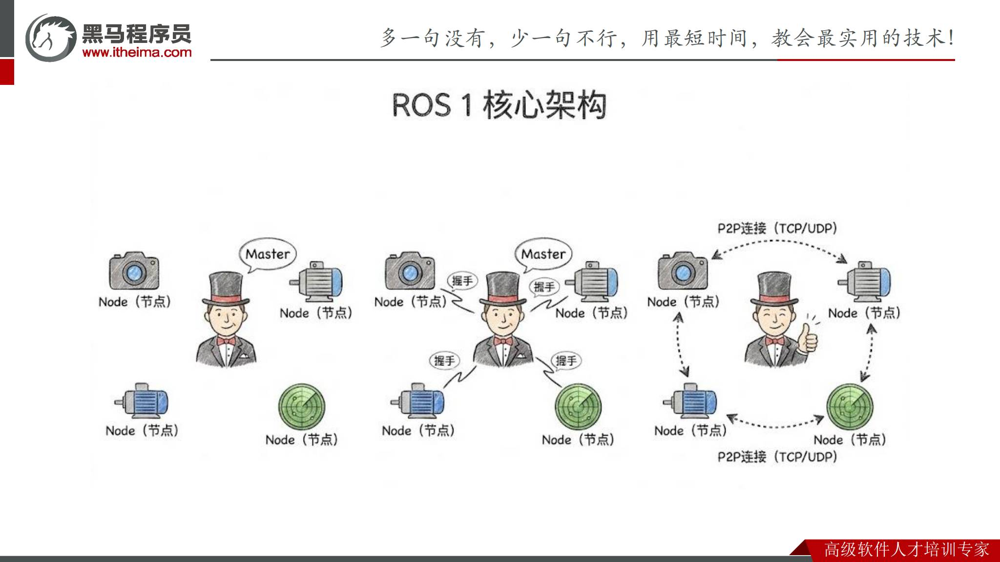

*原课件第9页：Master参与注册与发现，节点间随后直接通信。*

以话题订阅为例，理解流程即可，不必在本篇记住底层接口细节：

1. 发布节点向Master登记自己发布的话题和联系信息。
2. 订阅节点向Master登记订阅需求。
3. 订阅者获得发布者信息，与发布节点协商传输连接。
4. 建立连接后，消息主要在发布者与订阅者之间直接传输。

课件提到TCP/UDP。ROS1典型话题传输包括TCPROS与UDPROS，具体使用方式取决于实现和传输配置。

**重点：Master通常不是图像、点云等业务消息的中转站。**如果把所有消息都想象成必须经过Master，就会误解性能瓶颈和故障行为。

**工程补充：Master停止不等于所有已有数据连接立即中断。**已经建立的点对点连接可能继续传输；新的注册、发现、拓扑更新和需要重新发现的连接会受影响。Master仍是ROS1运行图的重要中心依赖，因此应同时理解“中心化风险”和“已有连接的实际行为”。


## 8. ROS1从实验室走向工业时遇到的挑战

实验室强调快速尝试和算法验证，工业环境更关注持续运行、异常恢复、时序要求和系统安全。课件通过真实环境与实验室的差异，解释ROS2出现的动机。

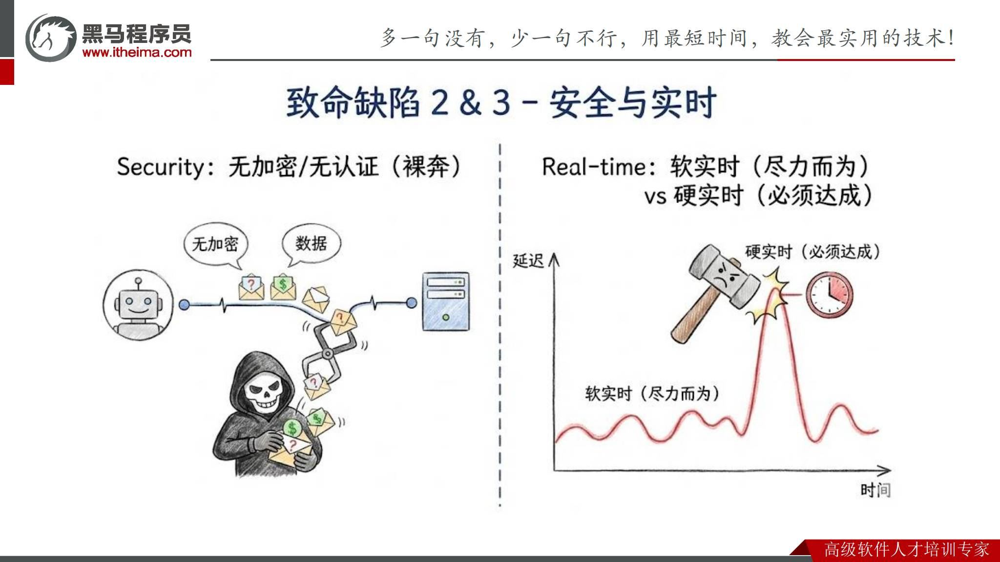

*原课件第12页：默认安全机制与实时响应能力的局限。*

| 挑战 | 含义 | 对机器人项目的影响 |
|---|---|---|
| 中心依赖 | 注册发现依赖Master | 故障恢复和动态加入模块更复杂 |
| 默认通信安全不足 | 默认缺少完整的身份认证、加密和权限体系 | 不能把可信实验网络的假设直接带入开放网络 |
| 实时性建设不足 | 普通运行环境中可能存在调度与通信抖动 | 严格时限任务需要额外设计 |
| 稳定性与部署复杂度 | 多模块、多设备、真实网络增加故障来源 | 需要监控、恢复和明确接口约定 |

**软实时：**偶尔错过时限会降低效果，例如画面更新迟缓。

**硬实时：**系统必须满足指定时限；错过期限就意味着关键要求失败。关注的是可证明、可控制的最坏情况，而不只是平均运行得快。

这些限制不能概括为“ROS1做不了工业机器人”或“ROS1不能用于自动驾驶研究”。更准确的认识是：面对工业系统的需求，ROS1需要较多额外工程措施，ROS2则在架构和基础能力上更重视这些需求。


## 9. ROS2的重构：DDS与去中心化发现

ROS2不是ROS1简单换版本号，而是围绕新的机器人需求重新设计了通信与运行体系。课件的核心变化是：**取消ROS1 Master，典型通信实现转向DDS。**

DDS全称为 **Data Distribution Service，数据分发服务**。它提供分布式数据通信的基础能力，支持发现、发布订阅和可配置的数据交付策略。

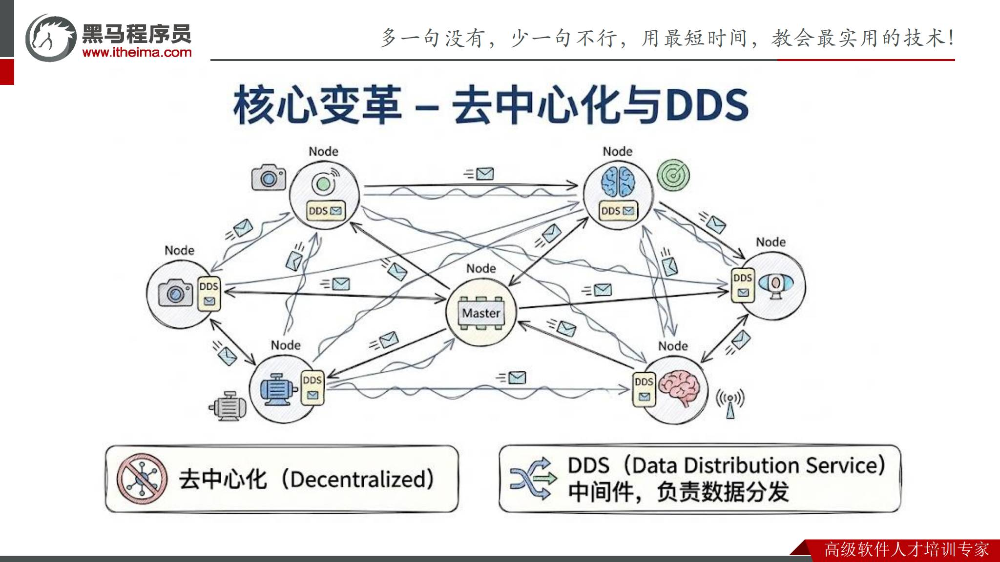

*原课件第16页：ROS2通过DDS组织分布式通信。*

概念上可以理解为：ROS2节点通过底层通信实现寻找合适的通信对象，并根据消息类型、话题及通信约定交换数据，不再依靠ROS1的Master完成注册发现。

**工程补充：**ROS2通过RMW（ROS Middleware）抽象连接底层通信实现，DDS是本课程重点和典型选择，不能把“ROS2”与“某一种DDS产品”完全等同。发现方式也可配置；某些部署使用发现服务器等机制，“去中心化”描述的是典型架构，不表示每种部署都没有任何中心组件。

**QoS预告：**通信不只有“收到/没收到”，还要考虑可靠性、历史缓存、数据保留等策略。发布者与订阅者的QoS需要兼容。第04篇再结合Topic通信展开。

去掉Master不会自动解决所有通信故障。消息类型、网络连通性、域配置、发现设置和QoS都可能影响节点能否互通。


## 10. ROS2的实时性、安全与跨平台能力

### 10.1 实时性：确定性比平均速度更重要

课件用ROS1普通Linux响应波动与实时环境的对照说明实时性，并强调“确定性大于速度”。例如控制任务要求每次都在10毫秒内完成，平均1毫秒但偶尔耗时100毫秒，仍不能满足该时限要求。

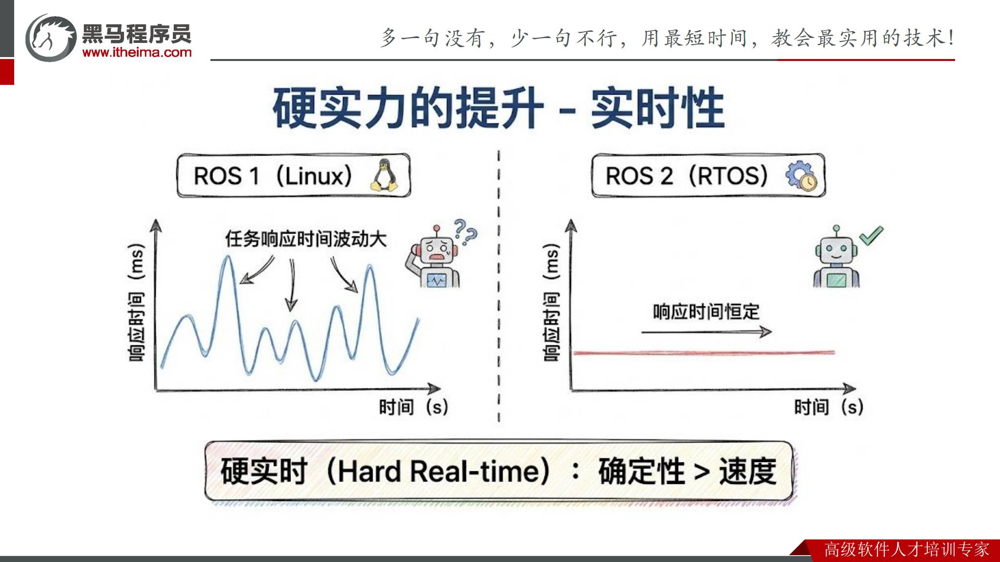

*原课件第17页：用响应波动解释确定性，图中属于简化的教学对比。*

**工程补充：ROS2不是RTOS，也不自动保证硬实时。**是否满足实时要求，取决于操作系统与调度、执行器和回调组织、动态内存操作、驱动、网络传输以及应用算法。实时系统需要分析完整链路的最坏执行时间和响应时间。

ROS2为构建实时系统提供了更合适的基础与相关支持，但安装ROS2、切换DDS或提高线程优先级都不能单独构成硬实时保证。

### 10.2 安全：提供能力，还要启用和配置

课件将ROS2安全能力概括为SROS。工程中常见SROS2工具与DDS Security配合，涉及身份认证、加密、完整性保护和访问权限。

**工程补充：**安全能力需要相应通信实现支持，并且要生成、部署和正确配置证书与权限。不能认为“使用ROS2后，所有节点默认已加密和认证”。

### 10.3 跨平台：按发行版确认支持

课件列出Linux、Windows、Mac等平台，强调ROS2相比ROS1更重视跨平台。实际选型应查看所用ROS2发行版的操作系统支持矩阵，同时检查驱动、依赖包与仿真工具。

框架可运行与项目所有组件都能运行，是两个需要分别验证的问题。本篇先建立概念，第02篇再以课件实际环境要求为准。


## 11. ROS1与ROS2对照：记架构，也记适用条件

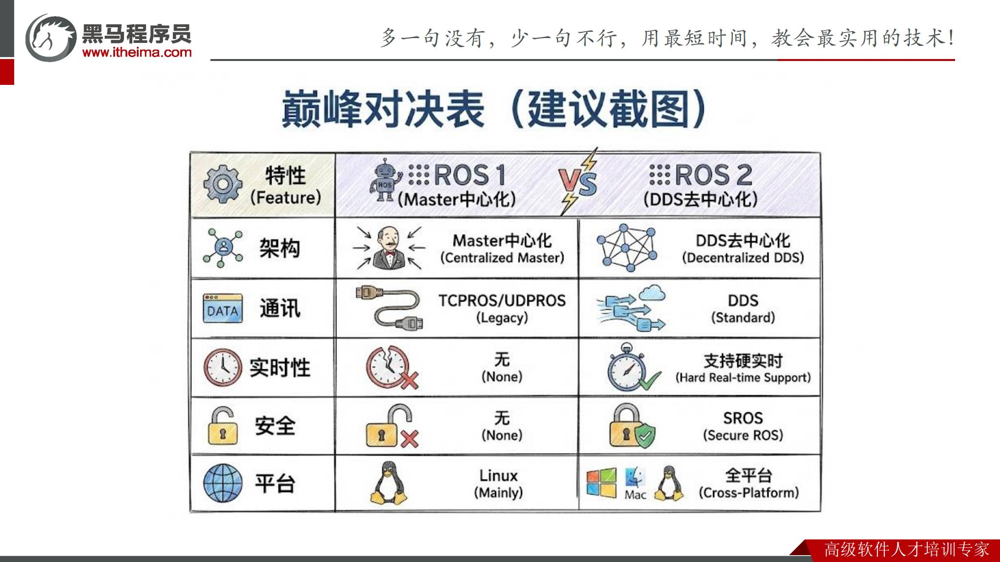

*原课件第19页：架构、通信、实时性、安全与平台对照；下表补充工程限定条件。*

| 维度 | ROS1 | ROS2 |
|---|---|---|
| 注册与发现 | 典型架构依赖Master | 无ROS1 Master，典型DDS实现支持分布式发现 |
| 话题通信 | TCPROS/UDPROS等 | 经RMW连接底层实现，典型为DDS |
| 实时性 | 原始设计对实时需求支持较弱 | 更重视实时系统需求，最终保证取决于整体系统 |
| 安全 | 默认缺少完整通信安全体系 | 可配置安全机制，需要启用及正确部署 |
| 平台 | 生态以Linux为主 | 更重视跨平台，具体支持依发行版而定 |
| 工程使用 | 存量系统可能受现有驱动、包和维护成本约束 | 新项目可优先评估，仍需检查组件兼容性 |

选型时不要只问“哪个更新”，还应检查：硬件驱动是否支持？需要的算法包是否可用？团队能否维护？部署平台是什么？有没有明确的时序要求？

对于新学习项目，本课程采用ROS2，可以直接沿课程路线学习。对于已有ROS1项目，迁移通常还涉及接口、工具、驱动和部署方式的调整。


## 12. AI与机器人：从命令执行走向目标理解

课件提出三条发展趋势：**具身智能、云机器人、微型化。**其中具身智能强调智能系统通过身体感知环境、执行动作并获得反馈。

“去厨房拿咖啡”是一条目标描述，背后可以包含：理解用户意图、识别厨房与咖啡、导航、确定抓取目标、规划机械臂动作、执行、检查结果。

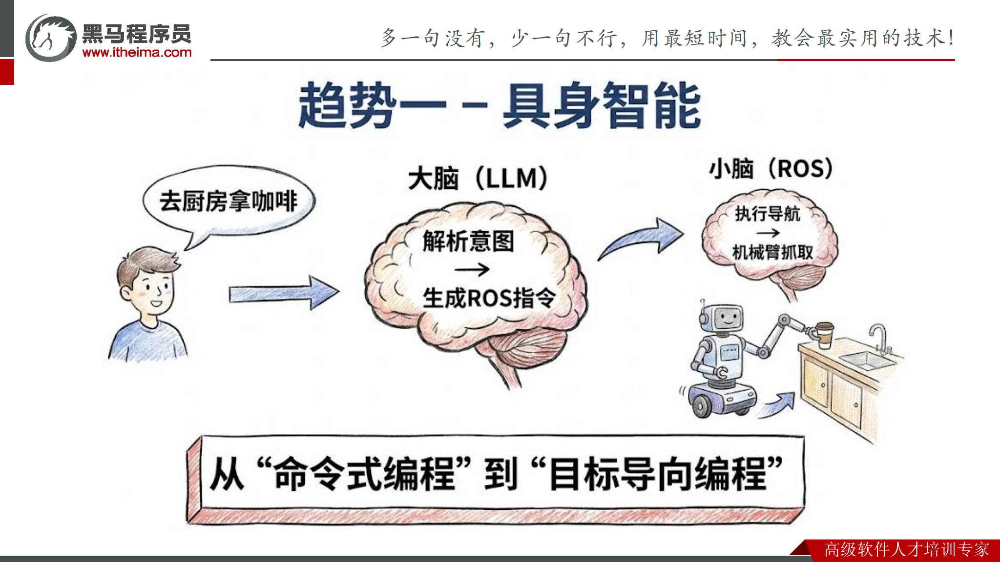

*原课件第21页：用“大脑”和“小脑”比喻LLM与机器人执行系统的分工。*

| 功能层 | 主要任务 | 示例 |
|---|---|---|
| 语言与任务理解 | 把自然语言转为结构化目标 | “拿咖啡”变成目标物、地点及步骤 |
| 任务组织 | 调用机器人已有能力并跟踪状态 | 导航成功后进入识别与抓取 |
| 感知和运动规划 | 处理传感器信息、生成轨迹 | 判断目标位置，规划避障路径 |
| 执行和反馈 | 驱动硬件，报告状态 | 执行关节运动，检测抓取结果 |

**工程补充：**ROS负责模块组织和通信，具体感知、规划和控制能力来自相关算法与组件。“ROS是小脑”是帮助入门的比喻，不等于ROS本身就是运动控制算法。

大模型生成的动作意图还需转换为受约束的接口调用：确认目标存在、参数与单位正确、动作在机器人能力范围内，并根据执行结果决定后续步骤。它不能仅凭一段自然语言就确定真实环境中已经完成任务。

例如“抓取物体”至少需要明确目标标识、坐标系、位姿、抓取方式和成功条件。任务层应基于机器人反馈继续执行，而不是在指令发出后就宣布完成。


## 13. 云机器人、micro-ROS与底层RTOS的衔接

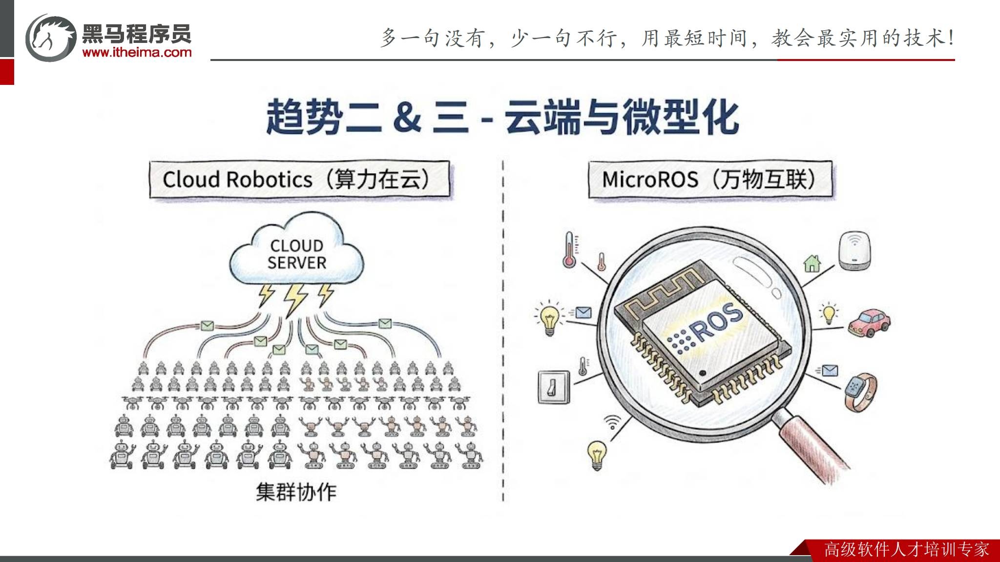

*原课件第22页：云计算、机器人集群与micro-ROS方向。*

**云机器人**可以把部分计算、模型服务和多机器人信息协作放在云端。机器人本地采集信息，必要时请求远端服务，再结合返回结果执行任务。实际部署还需考虑网络延迟、断网后的行为及本地必须保留的能力。

**micro-ROS**把ROS2生态延伸到资源受限的微控制器，使嵌入式端也能参与机器人数据通信。例如微控制器采集编码器数据，执行底层控制，再与上位机交换状态和目标值。

**工程补充：**micro-ROS典型采用Client/Agent架构，基于Micro XRCE-DDS把受限设备接入DDS系统。MCU侧运行轻量客户端，Agent在资源较充足的设备上衔接DDS通信。因此不能简单把普通ROS2的发现示意图原样套到MCU侧。

结合上一阶段RTOS课程，可以这样理解职责：

| 层次 | 典型职责 | 需要重点考虑 |
|---|---|---|
| 大模型/任务应用 | 解析目标、组织任务 | 输出约束、任务状态与反馈 |
| ROS2上位机 | 感知、规划、模块通信 | 坐标、时间戳、QoS和异常恢复 |
| MCU/RTOS | 采样、执行周期控制、处理硬件接口 | 截止时间、任务调度、共享资源 |
| 电机与传感器 | 产生物理动作和测量值 | 硬件特性、误差与执行范围 |

上述划分是工程示例，并非所有机器人都必须采用同一种结构。关键是把需要稳定时序的控制与高层任务处理合理组织起来。使用micro-ROS也不免除RTOS侧的调度与控制设计。


## 14. 知识树、课后作业与下一篇衔接

本篇的知识关系可以整理为：

```text
ROS：连接机器人软件模块的中间件与生态
├─ 起源：研究平台 → 开源复用 → 模块化生态
├─ ROS1
│  ├─ Node / Topic / Service
│  ├─ Master：注册与发现
│  └─ 主要挑战：中心依赖、安全、实时需求
├─ ROS2
│  ├─ 典型DDS通信，经RMW连接具体实现
│  ├─ 无ROS1 Master，支持分布式发现
│  └─ 实时、安全、跨平台：能力需要工程配置与验证
└─ 应用发展
   ├─ 具身智能：理解目标 → 感知规划 → 执行反馈
   ├─ 云机器人：计算服务与机器人集群协作
   └─ micro-ROS：受限MCU通过Client/Agent接入
```

### 14.1 课件作业：ROS2用什么取代Master？

**参考答案：**课件重点是DDS及其分布式发现和数据通信机制。ROS2取消ROS1的Master，典型DDS实现承担相应发现与通信功能；具体实现通过RMW接入，实际发现机制可配置。

注意不要回答“DDS是另一个Master服务器”。两者架构含义并不相同。

### 14.2 课件作业：简单循迹小车选ROS1还是ROS2？

**参考答案：**如果是跟随本课程的新项目，可优先学习和评估ROS2，便于后续接入视觉、语音与AI能力。最终仍要依据硬件资源、驱动和项目需求判断。

**工程补充：**如果小车只有微控制器，任务只是周期读取循迹传感器并控制电机，裸机或RTOS就可能满足需求，不一定需要完整ROS。若已有成熟ROS1系统，也应评估迁移成本。不能以“ROS2更新”为唯一理由，也不能把实时电机控制的要求直接转交给高层通信框架。

### 14.3 自测题

1. ROS为什么被称为中间件？——它利用操作系统能力，连接机器人模块并提供库、接口与工具。
2. Master是否转发每一帧图像？——典型ROS1话题数据在连接建立后直接传输。
3. Master停止后已有通信一定立即中断吗？——不一定，已有连接可能继续，新注册发现等受影响。
4. ROS2是否天然满足硬实时？——不是，需要分析和设计整个系统。
5. ROS2安全能力是否默认已正确启用？——不是，需要支持与配置。
6. LLM能否只凭文本确定抓取成功？——不能，应检查机器人执行反馈。
7. micro-ROS的MCU是否通常完整运行桌面DDS栈？——不是，典型架构通过轻量客户端和Agent衔接。

### 14.4 下一篇：开发环境搭建

第02篇对应《ROS环境搭建.pdf》，从实际课件中的系统与版本要求开始，建立ROS2运行和开发环境。本篇先理解概念，不提前替课件指定发行版或安装命令。

**延伸阅读入口（本篇工程补充的后续查阅方向）：**

- [ROS2与DDS设计](https://design.ros2.org/articles/ros_on_dds.html)
- [ROS2实时编程说明（Jazzy）](https://docs.ros.org/en/jazzy/Tutorials/Demos/Real-Time-Programming.html)
- [ROS2安全入门（Jazzy）](https://docs.ros.org/en/jazzy/Tutorials/Advanced/Security/Introducing-ros2-security.html)
- [micro-ROS功能概览](https://micro.ros.org/docs/overview/features/)

以上为官方文档入口，不表示本课程采用Jazzy；本篇未进行机器人硬件运行验证。
